# Portfolio-opdracht 1: Voorspel herseninfarct 

**Groep 3**

| Naam | Studentnummer | Kaggle-gebruikersnaam |
|---|---|---|
| Melih Bagci | 24099112 | Melih Bagci |
| Gamal Al Sabaeei | 25023497 | Gamal AL-sabaei |
| Rayan el Mourabit | 25025678 | Rayanell |

## 1. Inleiding

MedPredict is een medisch technologiebedrijf dat ziekenhuizen en zorginstellingen helpt om gezondheidsrisico's vroeg te herkennen. Het bedrijf beschikt over geanonimiseerde patiëntgegevens: demografische kenmerken, leefstijlfactoren en medische informatie.

Een herseninfarct is een groot gezondheidsprobleem: in 2021 was het wereldwijd de derde doodsoorzaak, goed voor ongeveer 10% van alle sterfgevallen (WHO, 2024). Als patiënten met een verhoogd risico eerder worden herkend, kunnen artsen hen gerichter opvolgen en preventieve zorg bieden.

MedPredict wil daarom weten of de patiëntgegevens gebruikt kunnen worden om deze risicopatiënten automatisch te herkennen. Om verschillende oplossingen te vergelijken, organiseert MedPredict een interne Kaggle-competitie tussen de teams van de opleiding Applied Data Science & AI.

Ons team (Groep 3) is als junior data scientists ingezet om dit model te ontwikkelen. Naast een goede score op Kaggle kijken we kritisch naar de data, onze keuzes en de betrouwbaarheid van het model, omdat verkeerde voorspellingen in deze medische toepassing gevolgen kunnen hebben voor patiënten.

## 2. Probleemstelling

MedPredict zoekt een model dat:
- patiënten met een herseninfarct zo goed mogelijk herkent (zo min mogelijk gemiste patiënten)
- niet te veel vals alarm geeft, omdat dat artsen tijd kost en patiënten onnodig ongerust maakt
- uitlegbaar is, zodat artsen de voorspelling kunnen vertrouwen en controleren

**Hoofdvraag:** in hoeverre kan een machine learning model op basis van persoonskenmerken, medische en leefstijlkenmerken herkennen welke patiënten een verhoogd risico op een herseninfarct hebben?

**Deelvragen:**
1. Hoe ziet de data eruit en is deze geschikt voor machine learning? 
2. Met welke metrics beoordelen we hoe goed een model is? 
3. Welk model presteert het best, en met welke hyperparameters? 
4. Welk model adviseren we aan artsen, en waarom? 

## 3. De dataset

### 3.1 Bestanden
De data komt uit de Kaggle-competitie Predicting stroke 2026-27. Elke rij is één geanonimiseerde patiënt.

| Bestand | Inhoud | 
|---|---|
| train.csv | 33.550 patiënten
| test.csv | 8.388 patiënten
| sample_submission.csv | Kolommen id en stroke 

### 3.2 Data inladen
We laden de train- en testset en bekijken de eerste vijf rijen.

In [2]:
"""Exploratieve data-analyse voor de Kaggle-competitie Predicting stroke."""
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train_df = pd.read_csv("../data/train.csv")
test_df = pd.read_csv("../data/test.csv")

print(train_df.shape, test_df.shape)

(33550, 22) (8388, 21)


In [3]:
train_df.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,...,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,...,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,...,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,...,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,...,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,...,False,False,True,False,True,False,True,False,False,0


**Observaties:**
- De trainset heeft 33.550 rijen en 22 kolommen, de testset heeft 8.388 rijen en 21 kolommen. De ontbrekende kolom in de test is de target stroke, die wij moeten voorspellen.
- Elke rij is één patiënt met een uniek id.

### 3.3 Beschrijving van de kolommen

De dataset bevat 22 kolommen.

| Kolom | Beschrijving | Meetniveau |
|---|---|---|
| id| Uniek nummer per patiënt | Nominaal |
| age | Leeftijd in jaren (baby's hebben decimalen, bijv. 0,08) | Ratio |
| hypertension | Hoge bloeddruk (1 = ja) | Nominaal |
| heart_disease | Hartziekte (1 = ja) | Nominaal  |
| avg_glucose_level | Gemiddelde bloedsuikerspiegel (mg/dL) | Ratio |
| bmi | Body Mass Index: gewicht (kg) / lengte² (m²) | Ratio |
| gender_Female / _Male / _Other | Geslacht | Nominaal |
| ever_married_No / _Yes | Ooit getrouwd geweest | Nominaal |
| work_type_Govt_job | Werkt bij de overheid | Nominaal |
| work_type_Never_worked | Heeft nooit gewerkt | Nominaal |
| work_type_Private | Werkt in de private sector | Nominaal |
| work_type_Self-employed | Zelfstandig ondernemer | Nominaal |
| work_type_children | Kind (werkt nog niet) | Nominaal |
| Residence_type_Rural / _Urban | Woont op het platteland / in de stad | Nominaal |
| smoking_status_formerly smoked | Heeft vroeger gerookt | Nominaal |
| smoking_status_never smoked | Heeft nooit gerookt | Nominaal |
| smoking_status_smokes | Rookt momenteel | Nominaal |
| stroke| Target: herseninfarct gehad (1 = ja, 0 = nee) | Nominaal  |

## 4. Exploratieve Data Analyse

In de EDA leren we de data kennen voordat we gaan modelleren. We onderzoeken hoe de data eruitziet, of deze bruikbaar is voor machine learning en welke kenmerken samenhangen met een herseninfarct. De bevindingen gebruiken we om keuzes te onderbouwen bij het opschonen van de data en bij het modelleren.


### 4.1 Datatypes en basisstatistieken

In [11]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  int32  
 7   gender_Male                     33550 non-null  int32  
 8   gender_Other                    33550 non-null  int32  
 9   ever_married_No                 33550 non-null  int32  
 10  ever_married_Yes                33550 non-null  int32  
 11  work_type_Govt_job              33550 non-null  int32  
 12  work_type_Never_worked          

**Observaties:**
- De trainset bevat 33.550 patiënten en 22 kolommen.
- Alle kolommen hebben 33.550 non-null waarden: er zijn geen ontbrekende waarden (NaN).
- Er zijn drie datatypes:
  - `float64` (3): `age`, `avg_glucose_level` en `bmi`, de numerieke features;
  - `int64` (4): `id`, `hypertension`, `heart_disease` en de target `stroke`;
  - `bool` (15): de dummy-kolommen (`True`/`False`).
- Er zijn geen tekstkolommen: alle data is al numeriek of boolean.

Voor de numerieke features (`age`, `avg_glucose_level` en `bmi`) tonen we de basisstatistieken: gemiddelde, standaardafwijking, minimum, kwartielen en maximum. Deze statistieken zijn alleen zinvol voor variabelen op ratio- of intervalniveau. Hiermee krijgen we inzicht in de spreiding van de data en kunnen we mogelijke uitschieters opsporen.

In [5]:
NUMERIC_COLS = ["age", "avg_glucose_level", "bmi"]

train_df[NUMERIC_COLS].describe().round(2)

,age,avg_glucose_level,bmi
count,33550.00,33550.00,33550.00
mean,41.82,103.59,28.60
std,22.48,42.13,7.78
min,0.08,55.01,10.10
25%,24.00,77.46,23.30
50%,43.00,91.32,27.70
75%,59.00,111.44,32.80
max,82.00,281.59,97.60


**Observaties:**
- **age** loopt van 0,08 tot 82 jaar: de dataset bevat ook baby's en kinderen. Het gemiddelde (41,8) en de mediaan (43,0) liggen dicht bij elkaar, dus de verdeling is redelijk symmetrisch.
- **avg_glucose_level** is **rechtsscheef**: het gemiddelde (103,6) ligt boven de mediaan (91,3). Een groep patiënten met een zeer hoge bloedsuiker trekt het gemiddelde omhoog. Het maximum (281,6) ligt ver boven het 75%-kwartiel (111,4).
- **bmi** ligt bij de helft van de patiënten tussen 23,3 en 32,8 (25%–75%). Het maximum van 97,6 is extreem, maar medisch niet onmogelijk (ernstig overgewicht).
- **De schalen verschillen sterk:** age loopt tot 82, avg_glucose_level tot 282 en bmi tot 98. Dit is van belang voor modellen die met afstanden werken.
  Bij avg_glucose_level en bmi ligt het maximum ver boven het 75%-kwartiel. Dit wijst op uitschieters: die onderzoeken we met de IQR-regel.

Voor binaire variabelen zijn een gemiddelde en standaardafwijking weinig betekenisvol. Daarom tonen we per kolom het aantal en het percentage patiënten met de waarde 1. Zo zien we hoe vaak elke categorie voorkomt en hoe onevenwichtig de target `stroke` is.

In [6]:
def binary_summary(df: pd.DataFrame, exclude: list[str]) -> pd.DataFrame:
    """Geef per binaire kolom het aantal en percentage enen (True / 1)."""
    binary_cols = [col for col in df.columns
                   if col not in exclude and df[col].nunique() == 2]
    summary = pd.DataFrame({
        # True telt als 1, dus de som is het aantal enen
        "aantal_1": df[binary_cols].sum().astype(int),
        # Het gemiddelde van 0/1 is het aandeel enen; x 100 geeft procenten
        "percentage_1": (df[binary_cols].mean() * 100).round(2),
    })
    return summary


binary_summary(train_df, exclude=["id"] + NUMERIC_COLS)

,aantal_1,percentage_1
hypertension,2957,8.81
heart_disease,1444,4.30
gender_Female,20032,59.71
gender_Male,13512,40.27
gender_Other,6,0.02
ever_married_No,12124,36.14
ever_married_Yes,21426,63.86
work_type_Govt_job,4156,12.39
work_type_Never_worked,141,0.42
work_type_Private,19279,57.46


**Observaties:**
- **De target stroke is sterk onevenwichtig:** slechts 517 patiënten (1,54%) hebben een herseninfarct gehad. Een model dat altijd "geen stroke" voorspelt, heeft al 98,5% goed.
- **Medische kenmerken:** 8,8% heeft hoge bloeddruk (hypertension) en 4,3% een hartziekte (heart_disease).
- **Zeer kleine groepen:** gender_Other komt maar 6 keer voor (0,02%) en work_type_Never_worked 141 keer (0,42%). Deze groepen zijn te klein om betrouwbaar iets van te leren.


In [7]:
# Duplicaten: id weglaten, want dat is per patiënt altijd uniek
print("Duplicaten (zonder id):", train_df.drop(columns="id").duplicated().sum())
# Hoeveel patiënten met gender_Other zitten er in de testset?
print("gender_Other in test:", test_df["gender_Other"].sum())

Duplicaten (zonder id): 0
gender_Other in test: 1


### 4.2 Geschiktheid voor scikit-learn

Scikit-learn stelt de volgende minimale eisen aan de data:
1. **Alle features zijn numeriek.** Categorische variabelen moeten omgezet zijn (bijv. met one-hot encoding).
2. **Geen ontbrekende waarden (NaN).** De meeste modellen kunnen hier niet mee omgaan.
3. **Features en target zijn gescheiden** in een feature-matrix X en een targetvector Y.
4. **De train- en testset hebben dezelfde features** in dezelfde volgorde.

Hieronder controleren we deze eisen.

In [8]:
def check_sklearn_ready(train: pd.DataFrame, test: pd.DataFrame,
                        target: str) -> None:
    """Controleer of de data voldoet aan de minimale eisen van scikit-learn."""
    features = train.drop(columns=target)
    non_numeric = features.select_dtypes(exclude=["number", "bool"]).columns
    print("Niet-numerieke kolommen:", list(non_numeric))
    print("Ontbrekende waarden train:", train.isna().sum().sum())
    print("Ontbrekende waarden test:", test.isna().sum().sum())
    print("Zelfde features in train en test:",
          list(features.columns) == list(test.columns))


check_sklearn_ready(train_df, test_df, target="stroke")

Niet-numerieke kolommen: []
Ontbrekende waarden train: 0
Ontbrekende waarden test: 0
Zelfde features in train en test: True


De dummy-kolommen hebben het datatype bool (True/False). Scikit-learn accepteert dit wel, maar we zetten ze om naar integers (1/0). Zo hebben alle binaire kolommen hetzelfde datatype en werken ze betrouwbaar. We passen dezelfde omzetting toe op de testset, zodat beide sets hetzelfde formaat hebben.

In [9]:
def bool_to_int(df: pd.DataFrame) -> pd.DataFrame:
    """Zet alle boolean kolommen om naar integers (0/1)."""
    df = df.copy()
    bool_cols = df.select_dtypes(include="bool").columns
    df[bool_cols] = df[bool_cols].astype(int)
    return df


train_df = bool_to_int(train_df)
test_df = bool_to_int(test_df)
print(train_df.dtypes.value_counts())

int32      15
int64       4
float64     3
Name: count, dtype: int64


**Conclusie:** de data voldoet aan de minimale eisen van scikit-learn. Alle kolommen zijn numeriek, er zijn geen ontbrekende waarden en de train- en testset hebben dezelfde features. De boolean dummy-kolommen zijn omgezet naar integers (0/1). De kolom id is niet relevant voor het model en wordt bij het opschonen verwijderd.

### 4.3 Relaties tussen features en target

#### 4.3.1 uitschieters

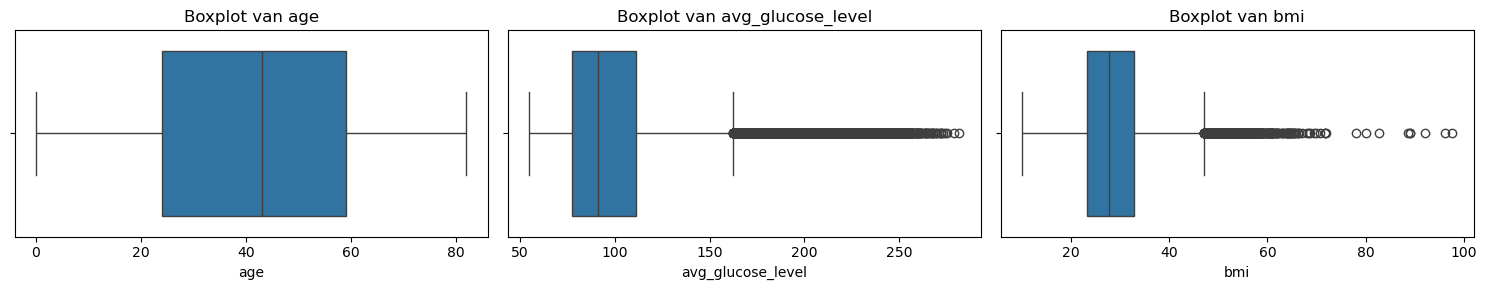

In [10]:
def plot_boxplots(df: pd.DataFrame, cols: list[str]) -> None:
    """Toon per numerieke kolom een boxplot om uitschieters te laten zien."""
    # Eén rij met een boxplot per kolom
    fig, axes = plt.subplots(1, len(cols), figsize=(15, 3))
    for ax, col in zip(axes, cols):
        # De losse rondjes in de boxplot zijn de uitschieters
        sns.boxplot(x=df[col], ax=ax)
        ax.set_title(f"Boxplot van {col}")
    plt.tight_layout()
    plt.show()


plot_boxplots(train_df, NUMERIC_COLS)

Observaties:
- **`age`** heeft **geen uitschieters**: alle leeftijden (0–82 jaar) liggen binnen de snorharen.
- **`avg_glucose_level`** heeft **veel uitschieters** boven ±162 mg/dL. Ze vormen een dikke zwarte balk tot 282 mg/dL. Dit zijn geen meetfouten, maar patiënten met een hoge bloedsuiker (bijv. diabetes).
- **`bmi`** heeft **uitschieters** boven ±47, met enkele extremen tussen 80 en 98. Zeldzaam, maar medisch mogelijk.
- **Conclusie:** we **behouden alle uitschieters**, omdat ze realistisch zijn en ook in de testset voorkomen.

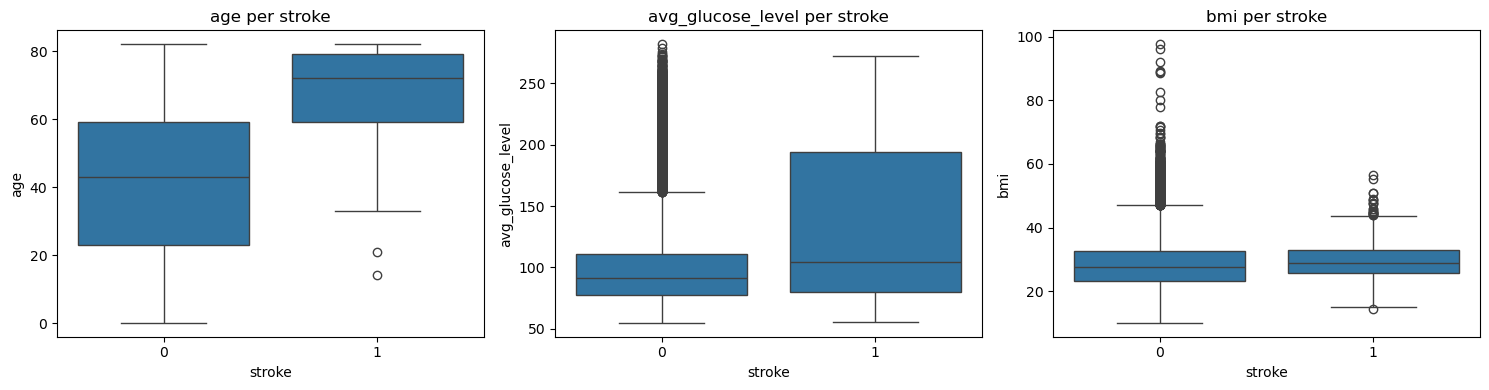

In [11]:
def plot_boxplot_per_stroke(df: pd.DataFrame, cols: list[str]) -> None:
    """Toon per numerieke feature een boxplot voor stroke = 0 en 1."""
    fig, axes = plt.subplots(1, len(cols), figsize=(15, 4))
    for ax, col in zip(axes, cols):
        # Vergelijk de waarden van patiënten zonder (0) en met (1) stroke
        sns.boxplot(data=df, x="stroke", y=col, ax=ax)
        ax.set_title(f"{col} per stroke")
    plt.tight_layout()
    plt.show()


plot_boxplot_per_stroke(train_df, NUMERIC_COLS)

**Observaties:**
- **`age`** heeft de duidelijkste relatie met `stroke`. De mediane leeftijd van patiënten met een herseninfarct is 72 jaar, tegenover 43 jaar bij patiënten zonder. Onder de 40 jaar komt een herseninfarct nauwelijks voor (alleen twee uitzonderingen rond 15 en 20 jaar).
- **`avg_glucose_level`** ligt hoger bij patiënten met een herseninfarct. Hun doos loopt door tot ongeveer 190 mg/dL, tegenover ongeveer 110 mg/dL bij patiënten zonder. De hoge waarden die voor de hele groep uitschieters zijn, zijn bij stroke-patiënten juist normaal. Een hoge bloedsuiker hangt dus samen met een verhoogd risico.
- **`bmi`** verschilt nauwelijks tussen beide groepen: de dozen liggen bijna op dezelfde hoogte. De extreme waarden (bmi > 60) komen alleen voor bij patiënten zonder herseninfarct.


#### 4.3.2 Binaire features

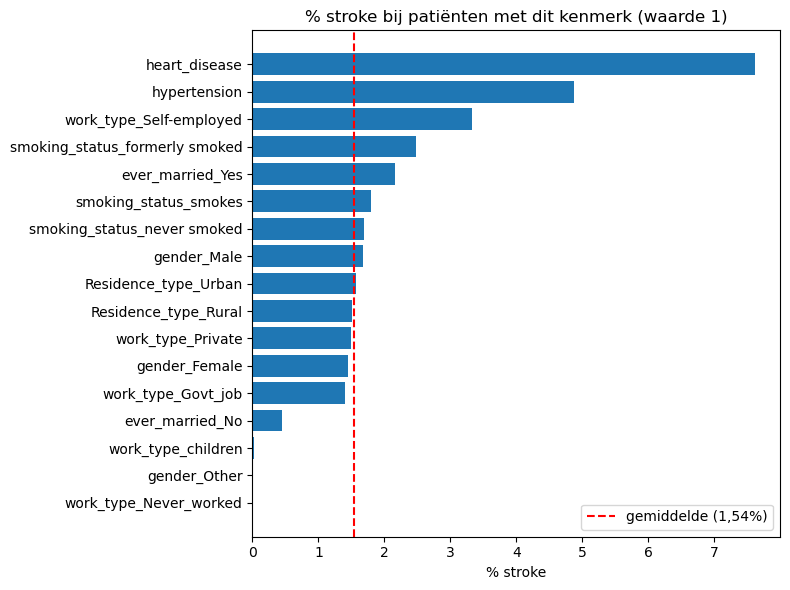

In [12]:
def plot_stroke_rate(df: pd.DataFrame, cols: list[str]) -> None:
    """Toon per binaire feature het % stroke bij patiënten met waarde 1."""
    # % stroke binnen de groep met waarde 1, gesorteerd van laag naar hoog
    rates = {col: df.loc[df[col] == 1, "stroke"].mean() * 100
             for col in cols}
    rates = pd.Series(rates).sort_values()

    plt.figure(figsize=(8, 6))
    plt.barh(rates.index, rates.values)
    # Rode stippellijn: gemiddelde % stroke van alle patiënten
    plt.axvline(df["stroke"].mean() * 100, color="red", linestyle="--",
                label="gemiddelde (1,54%)")
    plt.xlabel("% stroke")
    plt.title("% stroke bij patiënten met dit kenmerk (waarde 1)")
    plt.legend()
    plt.tight_layout()
    plt.show()


BINARY_COLS = [col for col in train_df.columns
               if col not in ["id", "stroke"] + NUMERIC_COLS]
plot_stroke_rate(train_df, BINARY_COLS)

**Observaties:**
- **`heart_disease`** en **`hypertension`** hebben de sterkste relatie met `stroke`: bij patiënten met een hartziekte is het percentage herseninfarcten ongeveer 6 keer zo hoog (7,6% vs. 1,25%), bij hoge bloeddruk ongeveer 4 keer zo hoog (4,9% vs. 1,2%).
- **`ever_married_Yes`**, **`work_type_Self-employed`** en **`smoking_status_formerly smoked`** laten een verhoogd percentage zien, terwijl **`work_type_children`** bijna geen herseninfarcten heeft. Dit wordt waarschijnlijk (deels) verklaard door **leeftijd**: getrouwde, zelfstandige en voormalige rokers zijn gemiddeld ouder. Leeftijd is hier een *confounder*.
- **`gender`**, **`Residence_type`**, **`work_type_Govt_job`**, **`work_type_Private`** en de overige rookcategorieën laten nauwelijks verschil zien.
- **`gender_Other`** en **`work_type_Never_worked`** bevatten geen enkele patiënt met een herseninfarct, omdat deze groepen erg klein zijn.

### 4.4 Correlatie met de target
We berekenen voor iedere feature de correlatie met `stroke` met de functie `.corr()` van pandas (Pearson). Een correlatie ligt tussen −1 en 1:
- **positief**: hoe hoger de feature, hoe vaker een herseninfarct;
- **negatief**: hoe hoger de feature, hoe minder vaak een herseninfarct;
- **dicht bij 0**: (bijna) geen lineair verband.

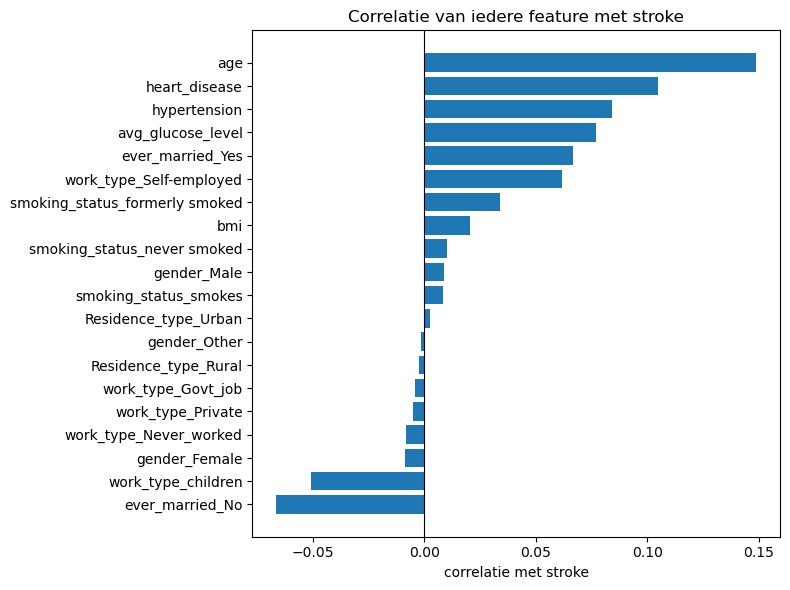

In [14]:
def plot_target_correlation(df: pd.DataFrame, target: str) -> None:
    """Toon de correlatie van iedere feature met de target."""
    # Correlatie van alle kolommen met de target (id telt niet mee)
    corr = df.drop(columns="id").corr()[target]
    # De target zelf weghalen (altijd 1) en sorteren
    corr = corr.drop(target).sort_values()

    plt.figure(figsize=(8, 6))
    plt.barh(corr.index, corr.values)
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("correlatie met stroke")
    plt.title("Correlatie van iedere feature met stroke")
    plt.tight_layout()
    plt.show()


plot_target_correlation(train_df, target="stroke")

**Observaties:**
- De sterkste correlaties met `stroke` zijn **`age`** (0,15), **`heart_disease`** (0,11), **`hypertension`** (0,08) en **`avg_glucose_level`** (0,08). 
- **`ever_married_No`** en **`work_type_children`** hebben een negatieve correlatie: deze groepen bestaan vooral uit jonge patiënten en hebben dus minder vaak een herseninfarct.
- **`gender`**, **`Residence_type`** en **`bmi`** hebben een correlatie van bijna 0: (bijna) geen verband met `stroke`.
- **Alle correlaties zijn laag (≤ 0,15).** Dat komt deels doordat maar 1,54% van de patiënten een herseninfarct heeft. Een lage correlatie betekent niet dat een feature nutteloos is: correlatie meet alleen een **lineair** verband, terwijl modellen zoals een decision tree ook andere verbanden kunnen gebruiken.

### 4.5 Belangrijkste bevindingen

1. **Sterk onevenwichtige target:** slechts 1,54% van de patiënten heeft een herseninfarct gehad.
2. **Leeftijd is de belangrijkste voorspeller:** herseninfarcten komen vrijwel alleen voor bij patiënten ouder dan 40 jaar (mediaan 72 tegenover 43 jaar).
3. **Medische factoren:** `heart_disease`, `hypertension` en een hoge `avg_glucose_level` verhogen het risico duidelijk.
4. **Leeftijd als confounder:** de verbanden bij `ever_married`, `work_type` en `smoking_status` worden waarschijnlijk grotendeels verklaard door leeftijd: deze groepen verschillen vooral in gemiddelde leeftijd.
5. **Zwakke features:** `gender`, `Residence_type` en `bmi` hebben nauwelijks een relatie met `stroke`.
6. **Datakwaliteit:** geen ontbrekende waarden en geen duplicaten. Wel is bij 30,8% de rookstatus onbekend, en zijn er realistische uitschieters in `avg_glucose_level` en `bmi` (tot 97,6). Deze behouden we.
7. **Zeer kleine groepen:** `gender_Other` (6 patiënten) en `work_type_Never_worked` (141 patiënten) zijn te klein om betrouwbaar iets van te leren.
8. **Redundante kolommen:** een aantal dummy-paren (bijv. `ever_married_No` / `_Yes`) bevat dezelfde informatie. Per paar verwijderen we er één (4.6).
9. **Verschillende schalen:** `age` loopt tot 82, `avg_glucose_level` tot 282 en `bmi` tot 98. Daarom onderzoeken we standaardisatie (4.7).

### 4.6 Data opschonen

Op basis van de EDA voeren we de volgende stappen uit:
1. **`id` verwijderen uit de features.** Dit is een willekeurig nummer zonder relatie met `stroke`. De id's van de testset bewaren we apart voor de Kaggle-submission.
2. **Patiënten met `gender_Other` verwijderen uit de trainset.** Deze groep bevat slechts 6 patiënten, te weinig om iets van te leren. Daarna bevat de kolom alleen nog nullen en wordt ze verwijderd. Uit de testset verwijderen we geen rijen, omdat Kaggle voor elke patiënt een voorspelling verwacht.
3. **Eén dummy per categorische variabele verwijderen.** Deze is volledig af te leiden uit de andere kolommen. Dit voorkomt perfecte multicollineariteit, wat vooral van belang is voor lineaire modellen zoals logistic regression. We verwijderen `gender_Female`, `ever_married_No`, `Residence_type_Rural` en `work_type_Never_worked` (de kleinste groep, 141 patiënten). Bij roken is dit niet nodig: de categorie *Unknown* heeft al geen eigen kolom.
4. **Onbekende rookstatus behouden** als aparte categorie (alle rookkolommen 0). Verwijderen zou 30,8% van de data kosten.
5. **Uitschieters in `avg_glucose_level` en `bmi` behouden.** Ze zijn zeldzaam, maar medisch realistisch en komen ook in de testset voor. Door ze te behouden leert het model ook met deze patiënten omgaan.
6. **Jonge kinderen behouden.** Een leeftijd van 0,08 jaar is realistisch (baby's) en deze groep komt ook in de testset voor.


In [22]:
# Kolommen die we verwijderen: id (geen betekenis), gender_Other (te kleine
# groep) en per categorische variabele één overbodige dummy
DROP_COLS = [
    "id",
    "gender_Other",
    "gender_Female",
    "ever_married_No",
    "work_type_Never_worked",
    "Residence_type_Rural",
]


def clean_data(train: pd.DataFrame, test: pd.DataFrame
               ) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series]:
    """Verwijder irrelevante rijen en kolommen uit de train- en testset."""
    # Bewaar de test-id's voor het inleverbestand van Kaggle
    test_ids = test["id"].copy()
    # Alleen in train: verwijder de 6 patiënten met gender_Other
    train = train[train["gender_Other"] == 0].copy()
    # Verwijder dezelfde kolommen uit train en test
    train = train.drop(columns=DROP_COLS)
    test = test.drop(columns=DROP_COLS)
    return train, test, test_ids


train_clean, test_clean, test_ids = clean_data(train_df, test_df)
print("Train:", train_clean.shape)
print("Test:", test_clean.shape)
print("Kolommen:", list(train_clean.columns))

Train: (33544, 16)
Test: (8388, 15)
Kolommen: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi', 'gender_Male', 'ever_married_Yes', 'work_type_Govt_job', 'work_type_Private', 'work_type_Self-employed', 'work_type_children', 'Residence_type_Urban', 'smoking_status_formerly smoked', 'smoking_status_never smoked', 'smoking_status_smokes', 'stroke']


**Resultaat:**
- **Train:** van 33.550 naar **33.544 rijen** (6 patiënten met `gender_Other` verwijderd) en van 22 naar **16 kolommen** (15 features + `stroke`).
- **Test:** het aantal rijen blijft **8.388**; van 21 naar **15 kolommen**. Train en test hebben dus dezelfde 15 features.
- De ene patiënt met `gender_Other` in de testset heeft na het verwijderen van de kolommen de waarde `gender_Male = 0` en wordt door het model dus als vrouw behandeld. Omdat het om slechts één patiënt gaat, heeft dit nauwelijks invloed op de resultaten.

### 4.7 Standaardisatie

**Wat is standaardiseren?**
Bij standaardiseren zetten we elke numerieke feature om naar een schaal met gemiddelde 0 en standaardafwijking 1:

$$z = \frac{x - \mu}{\sigma}$$

waarbij $\mu$ het gemiddelde en $\sigma$ de standaardafwijking van de feature is. Een waarde van $z = 2$ betekent dus: twee standaardafwijkingen boven het gemiddelde.

**Wanneer is dit gewenst?**
- Bij modellen die met **afstanden** werken, zoals **K-Nearest Neighbors** en **SVM**. Zonder standaardisatie domineert de feature met de grootste getallen de afstand.
- Bij modellen die met **gradient descent** en **regularisatie** werken, zoals **logistic regression**. Standaardisatie zorgt dat het algoritme sneller convergeert en dat de regularisatie alle features even zwaar straft.
- **Niet nodig** bij **decision trees** en ensembles daarvan (random forest, gradient boosting). Deze splitsen op één feature tegelijk, waardoor de schaal geen invloed heeft.

**Voegt het waarde toe voor deze dataset?**
Ja. De numerieke features hebben sterk verschillende schalen: `age` loopt van 0 tot 82, `avg_glucose_level` van 55 tot 282 en `bmi` van 10 tot 98. Zonder standaardisatie zou `avg_glucose_level` bij KNN en SVM onterecht zwaarder wegen.

We standaardiseren alleen de numerieke features. De binaire features (0/1) laten we ongewijzigd, zodat hun betekenis behouden blijft.



Hieronder tonen we het gemiddelde en de standaardafwijking van de numerieke features voor en na standaardisatie.

In [21]:
from sklearn.preprocessing import StandardScaler


def show_standardization(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Toon gemiddelde en standaardafwijking voor en na standaardisatie."""
     # Standaardiseer de kolommen: (x - gemiddelde) / standaardafwijking
    scaled = StandardScaler().fit_transform(df[cols])
    # fit_transform geeft een array terug; zet die om naar een DataFrame
    scaled_df = pd.DataFrame(scaled, columns=cols)
    # Vergelijk gemiddelde en standaardafwijking voor en na
    return pd.DataFrame({
        "gemiddelde_voor": df[cols].mean(),
        "std_voor": df[cols].std(),
        "gemiddelde_na": scaled_df.mean().values,
        "std_na": scaled_df.std().values,
    }).round(2)


show_standardization(train_clean, NUMERIC_COLS)

,gemiddelde_voor,std_voor,gemiddelde_na,std_na
age,41.82,22.48,0.0,1.0
avg_glucose_level,103.59,42.13,0.0,1.0
bmi,28.60,7.78,-0.0,1.0


**Conclusie:** na standaardisatie hebben alle drie de numerieke features een gemiddelde van 0 en een standaardafwijking van 1. Ze liggen nu op dezelfde schaal en wegen daardoor even zwaar mee bij modellen die met afstanden of gradient descent werken. (De waarde -0,0 is het gevolg van afronding van een zeer klein getal en is in feite 0.)